C:\Users\39084\AppData\Local\Temp\ipykernel_10580\3414223603.py:51: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


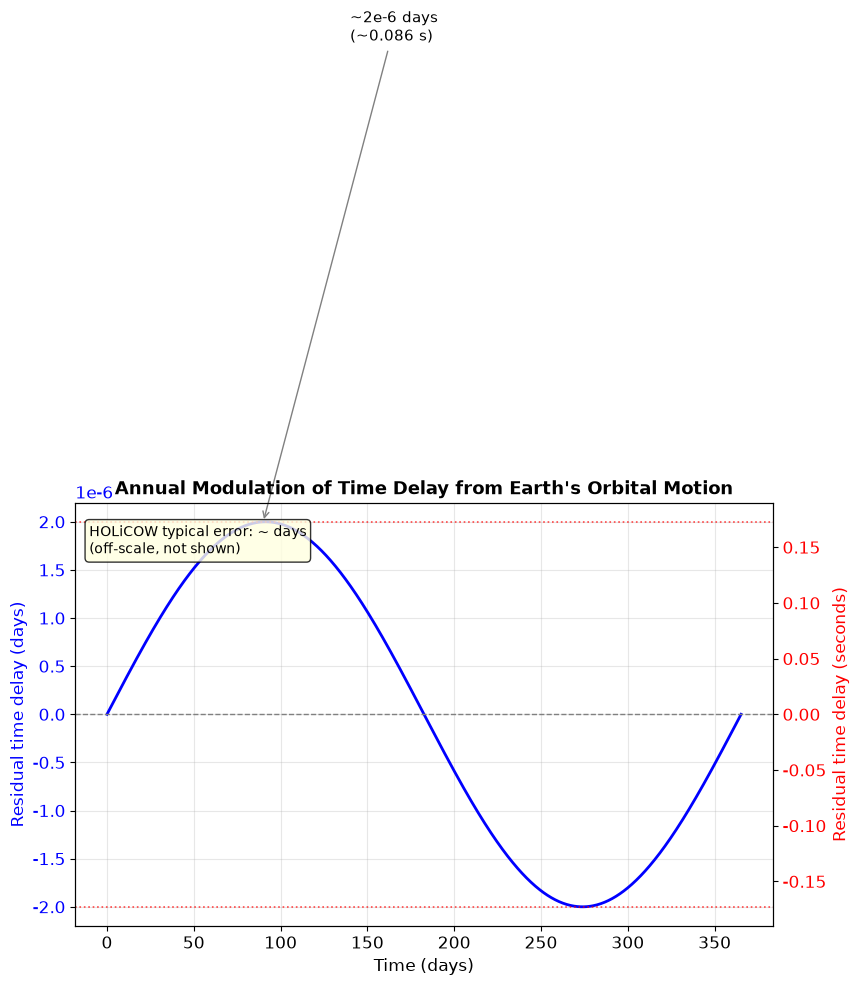

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.colors import TwoSlopeNorm
import os

plt.rcParams['font.size'] = 12
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

os.makedirs('figures', exist_ok=True)
# 图3：地球轨道运动对时间延迟的残余调制
days = np.linspace(0, 365.25, 1000)
amplitude = 2e-6
period = 365.25

residual_days = amplitude * np.sin(2 * np.pi * days / period)

fig, ax1 = plt.subplots(figsize=(9, 5.5))

ax1.plot(days, residual_days, 'b-', lw=2, label='Residual time delay')
ax1.axhline(0, color='gray', ls='--', lw=1)
ax1.axhline(amplitude, color='red', ls=':', lw=1.2, alpha=0.7,
            label='+/- 2e-6 days')
ax1.axhline(-amplitude, color='red', ls=':', lw=1.2, alpha=0.7)

ax1.set_xlabel('Time (days)')
ax1.set_ylabel('Residual time delay (days)', color='b')
ax1.tick_params(axis='y', labelcolor='b')
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.set_ylabel('Residual time delay (seconds)', color='r')
ax2.tick_params(axis='y', labelcolor='r')
ax2.set_ylim(ax1.get_ylim()[0] * 86400, ax1.get_ylim()[1] * 86400)

ax1.annotate('~2e-6 days\n(~0.086 s)',
             xy=(90, amplitude), xytext=(140, amplitude * 3.5),
             arrowprops=dict(arrowstyle='->', color='gray'),
             fontsize=11, ha='left')

ax1.text(0.02, 0.95,
         'HOLiCOW typical error: ~ days\n(off-scale, not shown)',
         transform=ax1.transAxes, fontsize=10,
         verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

ax1.set_title("Annual Modulation of Time Delay from Earth's Orbital Motion",
              fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('figures/fig3_observer_motion.png', dpi=300, bbox_inches='tight')
plt.show()